# Autoregressive Model Training for target `delta_p`

This notebook trains direct multi-horizon models for:
- 1 hour ahead
- 24 hours ahead
- 48 hours ahead

Models trained:
- Decision Tree
- Random Forest
- SVR
- CatBoost
- XGBoost
- LightGBM
- MLP
- LSTM (TensorFlow/Keras)

In [5]:
import json
from utils.paths import DATASETS_PREPROCESSED_DIR
import pandas as pd
import numpy as np
from sklearn.base import clone
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit, KFold
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, mean_absolute_percentage_error
from matplotlib import pyplot as plt
import pickle
from pathlib import Path

Since RandomizedSearchCV handles internal cross-validation by automatically splitting 
the training data into train and validation folds, the train and validation sets 
can be merged into a single training set.

In [6]:
train_df = pd.read_csv(DATASETS_PREPROCESSED_DIR / "Location_1_train.csv")
test_df = pd.read_csv(DATASETS_PREPROCESSED_DIR / "Location_1_test.csv")
df = pd.concat([train_df, test_df])
df

,time,temperature_2m,relative_humidity_2m,dew_point_2m,wind_speed_10m,wind_speed_100m,wind_gusts_10m,wind_sin_10m,wind_cos_10m,wind_sin_100m,wind_cos_100m,p_base,delta_p
0,2017-01-02 00:00:00,0.395392,0.817073,0.445396,0.0,0.000000,0.032143,5.591929e-01,-0.829038,0.309017,-0.951057,0.004818,-0.004818
1,2017-01-02 01:00:00,0.394470,0.829268,0.447537,0.0,0.085413,0.139286,4.848096e-01,-0.874620,0.374607,-0.927184,0.159005,-0.016605
2,2017-01-02 02:00:00,0.379724,0.890244,0.445396,0.0,0.000000,0.096429,5.299193e-01,-0.848048,0.500000,-0.866025,0.004818,-0.004818
3,2017-01-02 03:00:00,0.385253,0.853659,0.443255,0.0,0.000000,0.039286,8.480481e-01,0.529919,0.965926,-0.258819,0.004818,-0.004818
4,2017-01-02 04:00:00,0.384332,0.853659,0.441113,0.0,0.127639,0.125000,8.480481e-01,0.529919,0.994522,0.104528,0.185026,-0.105726
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,2021-12-31 19:00:00,0.447005,0.926829,0.531049,0.0,0.000000,0.071429,7.986355e-01,0.601815,0.681998,-0.731354,0.004818,-0.004818
8756,2021-12-31 20:00:00,0.453456,0.926829,0.540685,0.0,0.115163,0.153571,8.290376e-01,0.559193,0.951057,0.309017,0.182222,0.024378
8757,2021-12-31 21:00:00,0.447005,0.939024,0.536403,0.0,0.000000,0.135714,-2.449294e-16,1.000000,0.707107,0.707107,0.004818,-0.004818
8758,2021-12-31 22:00:00,0.449770,0.951220,0.541756,0.0,0.145873,0.132143,7.071068e-01,0.707107,0.777146,0.629320,0.217592,0.043008


Adding some additional time series features might be beneficial for pattern identification.

In [9]:
def create_time_features(df):
    df = df.sort_values("time").reset_index(drop=True)
    df["time"] = pd.to_datetime(df["time"])
    df['hour'] = df['time'].dt.hour
    df['dayofweek'] = df['time'].dt.dayofweek
    df['month'] = df['time'].dt.month

    return df

df = create_time_features(df)
df

,time,temperature_2m,relative_humidity_2m,dew_point_2m,wind_speed_10m,wind_speed_100m,wind_gusts_10m,wind_sin_10m,wind_cos_10m,wind_sin_100m,wind_cos_100m,p_base,delta_p,hour,dayofweek,month
0,2017-01-02 00:00:00,0.395392,0.817073,0.445396,0.0,0.000000,0.032143,5.591929e-01,-0.829038,0.309017,-0.951057,0.004818,-0.004818,0,0,1
1,2017-01-02 01:00:00,0.394470,0.829268,0.447537,0.0,0.085413,0.139286,4.848096e-01,-0.874620,0.374607,-0.927184,0.159005,-0.016605,1,0,1
2,2017-01-02 02:00:00,0.379724,0.890244,0.445396,0.0,0.000000,0.096429,5.299193e-01,-0.848048,0.500000,-0.866025,0.004818,-0.004818,2,0,1
3,2017-01-02 03:00:00,0.385253,0.853659,0.443255,0.0,0.000000,0.039286,8.480481e-01,0.529919,0.965926,-0.258819,0.004818,-0.004818,3,0,1
4,2017-01-02 04:00:00,0.384332,0.853659,0.441113,0.0,0.127639,0.125000,8.480481e-01,0.529919,0.994522,0.104528,0.185026,-0.105726,4,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43795,2021-12-31 19:00:00,0.447005,0.926829,0.531049,0.0,0.000000,0.071429,7.986355e-01,0.601815,0.681998,-0.731354,0.004818,-0.004818,19,4,12
43796,2021-12-31 20:00:00,0.453456,0.926829,0.540685,0.0,0.115163,0.153571,8.290376e-01,0.559193,0.951057,0.309017,0.182222,0.024378,20,4,12
43797,2021-12-31 21:00:00,0.447005,0.939024,0.536403,0.0,0.000000,0.135714,-2.449294e-16,1.000000,0.707107,0.707107,0.004818,-0.004818,21,4,12
43798,2021-12-31 22:00:00,0.449770,0.951220,0.541756,0.0,0.145873,0.132143,7.071068e-01,0.707107,0.777146,0.629320,0.217592,0.043008,22,4,12


Next thing to do is vizualize how data will be split for model finetuning.

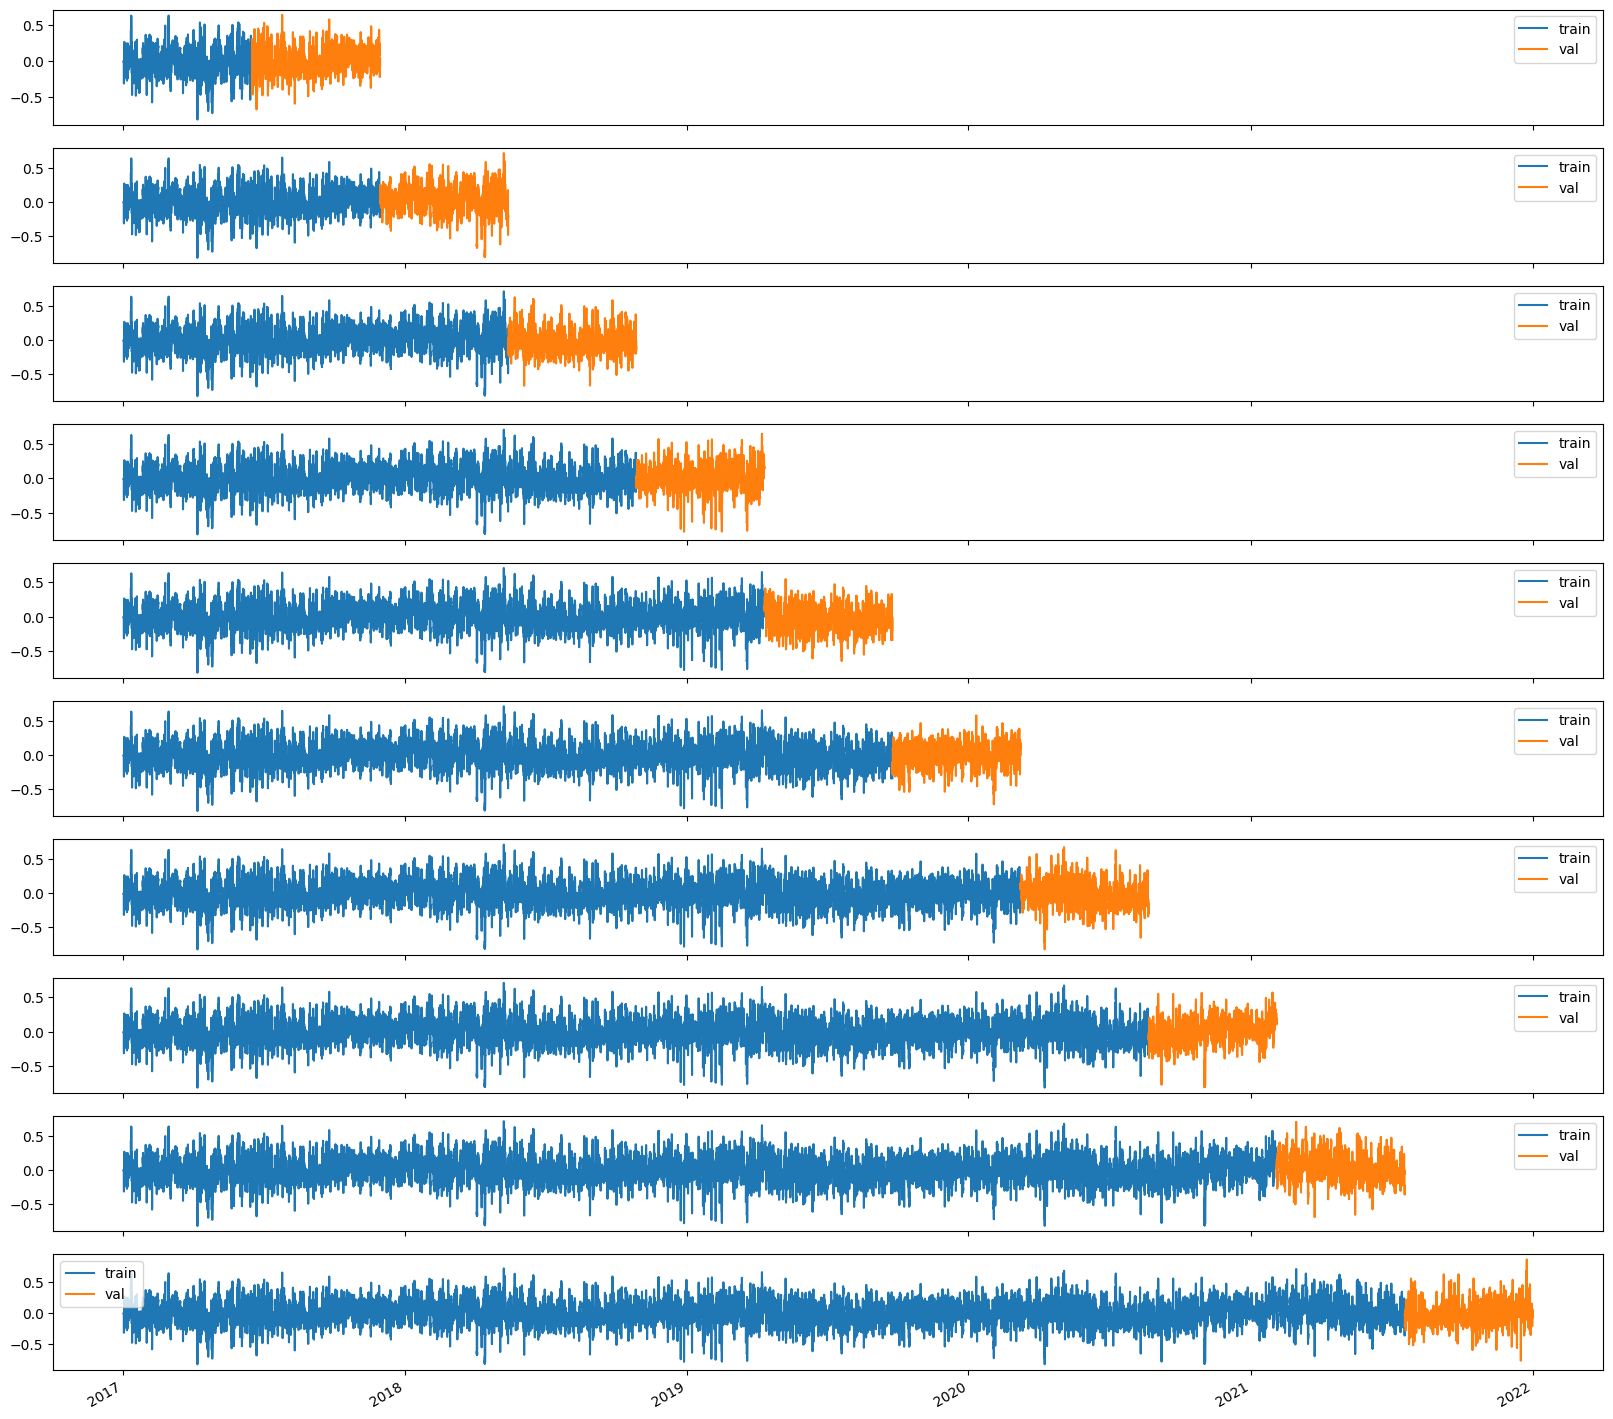

In [10]:
tss = TimeSeriesSplit(n_splits=10)

fig, axs = plt.subplots(10, 1, figsize=(20, 20), sharex=True)
fold = 0
for train_index, val_index in tss.split(df):
    train = df.iloc[train_index]
    val = df.iloc[val_index]
    axs[fold].plot(train["time"], train["delta_p"], label="train")
    axs[fold].plot(val["time"], val["delta_p"], label="val")
    axs[fold].legend()
    fold += 1
fig.autofmt_xdate()

A dedicated function handles lag feature engineering. Target lags (delta_p at t-1 through t-6, t-24, t-48) 
are selected based on ACF and PACF analysis of the target series. Feature lags are selected based 
on CCF analysis between each feature and the target. The prediction target is defined as delta_p 
shifted by -horizon, representing the value horizon steps ahead.

In [11]:
TARGET_LAGS = [1, 2, 3, 4, 5, 6, 24, 48]

FEATURE_LAGS = {
    "temperature_2m": [1, 17],
    "relative_humidity_2m": [6, 30],
    "wind_speed_10m": [6, 30],
    "wind_gusts_10m": [6, 30],
}


def add_lags(df, target_lags, feature_lags, horizon):
    lagged = df.copy()

    for lag in target_lags:
        lagged[f"delta_p_lag_{lag}"] = lagged["delta_p"].shift(lag)

    for feature, lags in feature_lags.items():
        for lag in lags:
            lagged[f"{feature}_lag_{lag}"] = lagged[feature].shift(lag)

    lagged["target"] = lagged["delta_p"].shift(-horizon)
    
    lagged = lagged.dropna().reset_index(drop=True)

    return lagged

Fine tuning is done using RandomizedSearchCV

In [49]:
INNER_SPLITS = 2
N_ITER_SEARCH = 20

MODELS_DIR = Path("autoregression-models/models")
MODELS_DIR.mkdir(exist_ok=True)

dt_params = {
    "max_depth": [None, 3, 5, 10, 20],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "max_features": [None, "sqrt", "log2", 0.5],
    "criterion": ["squared_error", "friedman_mse", "absolute_error"],
    "splitter": ["best", "random"],
}

rf_params = {
    "n_estimators": [50, 100, 150, 200],
    "max_depth": [2, 3, 5, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "max_features": [None, "sqrt", "log2", 0.5],
    "max_samples": [None, 0.7, 0.8, 0.9],
}

svr_params = {
    "C": [0.01, 0.1, 0.5, 1, 2],
    "epsilon": [0.01, 0.1, 0.5],
    "kernel": ["linear", "rbf", "poly", "sigmoid"],
    "gamma": ["scale", "auto"],
    "degree": [2, 3, 4],
    "coef0": [0.0, 0.1, 0.5, 1.0],
}

catboost_params = {
    "iterations": [100, 300, 500],
    "learning_rate": [0.01, 0.05, 0.1],
    "depth": [4, 6, 8, 10],
    "l2_leaf_reg": [1, 3, 5, 10],
    "verbose": [0],
}

xgboost_params = {
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [3, 5, 7, 10],
    "subsample": [0.5, 0.8, 1.0],
    "reg_alpha": [0, 0.1, 0.5, 1.0],
    "reg_lambda": [0, 0.1, 0.5, 1.0],
    "min_child_weight": [1, 3, 5],
    "gamma": [0, 0.1, 0.3],
}

lgbm_params = {
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "num_leaves": [20, 31, 40, 50],
    "max_depth": [3, 5, 10, 15],
    "min_child_samples": [10, 20, 50],
    "subsample": [0.5, 0.8, 1.0],
    "reg_alpha": [0, 0.1, 0.5, 1.0],
    "reg_lambda": [0, 0.1, 0.5, 1.0],
    "verbose": [-1],
}

mlp_params = {
    "hidden_layer_sizes": [
        (32,),
        (64,),
        (32, 16),
        (64, 32),
        (32, 16, 8),
        (64, 32, 16),
    ],
    "activation": ["relu", "tanh"],
    "solver": ["adam", "sgd"],
    "alpha": [0.001, 0.01, 0.1],
    "learning_rate": ["constant", "adaptive"],
    "learning_rate_init": [0.001, 0.01, 0.05],
    "max_iter": [1000, 1500, 2000],
    "early_stopping": [True],
}

models = {
    "decision_tree": (DecisionTreeRegressor(random_state=42), dt_params),
    "random_forest": (RandomForestRegressor(random_state=42), rf_params),
    "svr": (SVR(max_iter=1000), svr_params),
    "catboost": (CatBoostRegressor(random_state=42), catboost_params),
    "xgboost": (XGBRegressor(random_state=42, objective="reg:squarederror"), xgboost_params),
    "lgbm": (LGBMRegressor(random_state=42), lgbm_params),
    "mlp": (MLPRegressor(random_state=42), mlp_params),
}

HORIZONS = [1, 24, 48]
feature_drop_cols = ["time", "p_base", "delta_p", "target"]
nested_best_params = {}
nested_rows = []

for horizon in HORIZONS:
    print(f"=== Nested CV | Horizon {horizon}h ===")
    
    lagged_all = add_lags(df, TARGET_LAGS, FEATURE_LAGS, horizon).dropna().reset_index(drop=True)
    X_all = lagged_all.drop(columns=feature_drop_cols).copy()
    y_all = lagged_all["target"].copy()
    
    for split_idx, (outer_train_idx, outer_test_idx) in enumerate(tss.split(X_all), start=1):
        X_outer_train = X_all.iloc[outer_train_idx]
        y_outer_train = y_all.iloc[outer_train_idx]
        X_outer_test = X_all.iloc[outer_test_idx]
        y_outer_test = y_all.iloc[outer_test_idx]
        
        inner_tss = TimeSeriesSplit(n_splits=INNER_SPLITS)
        
        for model_name, (model, param_grid) in models.items():
            print(f"[{horizon}h] tuning model: {model_name}")
            
            nested_search = RandomizedSearchCV(
                estimator=clone(model),
                param_distributions=param_grid,
                n_iter=N_ITER_SEARCH,
                cv=inner_tss,
                scoring="neg_root_mean_squared_error",
                n_jobs=-1,
            )
            
            nested_search.fit(X_outer_train, y_outer_train)
            best_model = nested_search.best_estimator_
            y_pred = best_model.predict(X_outer_test)
            
            nested_best_params[f"{model_name}_h{horizon}_split{split_idx}"] = nested_search.best_params_

            model_path = MODELS_DIR / f"{model_name}_h{horizon}_s{split_idx}.pkl"
            with open(model_path, "wb") as f:
                pickle.dump(best_model, f)
            
            nested_rows.append(
                {
                    "horizon": horizon,
                    "outer_split": split_idx,
                    "model": model_name,
                    "MAE": mean_absolute_error(y_outer_test, y_pred),
                    "RMSE": root_mean_squared_error(y_outer_test, y_pred),
                    "R2": r2_score(y_outer_test, y_pred),
                    "MAPE": mean_absolute_percentage_error(y_outer_test, y_pred),
                }
            )

            print(
                f"[{horizon}h | split {split_idx}] done: {model_name} "
                f"with {nested_rows[-1]['RMSE']:.4f} RMSE"
            )
            

classical_metrics_df = pd.DataFrame(nested_rows).sort_values(["horizon", "model", "outer_split"]).reset_index(drop=True)
classical_metrics_df

=== Nested CV | Horizon 1h ===
[1h] tuning model: decision_tree
[1h | split 1] done: decision_tree with 0.1049 RMSE
[1h] tuning model: random_forest
[1h | split 1] done: random_forest with 0.1022 RMSE
[1h] tuning model: svr


/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/l

[1h | split 1] done: svr with 0.1046 RMSE
[1h] tuning model: catboost
[1h | split 1] done: catboost with 0.1019 RMSE
[1h] tuning model: xgboost
[1h | split 1] done: xgboost with 0.1011 RMSE
[1h] tuning model: lgbm
[1h | split 1] done: lgbm with 0.1014 RMSE
[1h] tuning model: mlp


/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1500) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1500) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/rafalzalecki/studia/coding/projekt_naukowo_wdroz

[1h | split 1] done: mlp with 0.1114 RMSE
[1h] tuning model: decision_tree
[1h | split 2] done: decision_tree with 0.1110 RMSE
[1h] tuning model: random_forest
[1h | split 2] done: random_forest with 0.1053 RMSE
[1h] tuning model: svr


/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/l

... (82 outputs left out)

[48h | split 10] done: svr with 0.1703 RMSE
[48h] tuning model: catboost
[48h | split 10] done: catboost with 0.1564 RMSE
[48h] tuning model: xgboost
[48h | split 10] done: xgboost with 0.1557 RMSE
[48h] tuning model: lgbm
[48h | split 10] done: lgbm with 0.1560 RMSE
[48h] tuning model: mlp


/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/numpy/_core/_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/neural_network/_base.py:188: RuntimeWarning: overflow encountered in square
  0.5 * np.average((y_true - y_pred) ** 2, weights=sample_weight, axis=0).mean()
/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/neural_network/_base.py:139: RuntimeWarning: invalid value encountered in multiply
  delta *= 1 - Z**2
/Users/rafalzalecki/studia/coding/projekt_naukowo_wdrozeniowy/projekt-naukowo-wdrozeniowy/.venv/lib/python3.14/site-packages/numpy/_core/_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = um

[48h | split 10] done: mlp with 0.1567 RMSE


,horizon,outer_split,model,MAE,RMSE,R2,MAPE
0,1,1,catboost,0.075072,0.101864,0.509471,3.549871
1,1,2,catboost,0.080276,0.109371,0.608069,2.380173
2,1,3,catboost,0.071528,0.098676,0.562159,3.336801
3,1,4,catboost,0.075067,0.106906,0.608202,2.763947
4,1,5,catboost,0.071203,0.098120,0.573593,2.806757
...,...,...,...,...,...,...,...
205,48,6,xgboost,0.115382,0.148049,0.019684,1.374210
206,48,7,xgboost,0.107861,0.148201,0.033570,1.592132
207,48,8,xgboost,0.122465,0.165852,0.017768,1.654780
208,48,9,xgboost,0.124073,0.164571,-0.028725,1.582408


In [12]:
from pathlib import Path

results_dir = Path("autoregression-models/results")

best_params_path = results_dir / "best_params_all.json"
metrics_path = results_dir / "classical_metrics_df.csv"

with open(best_params_path, "w", encoding="utf-8") as f:
    json.dump(nested_best_params, f, indent=2)

classical_metrics_df.to_csv(metrics_path, index=False)

print(f"Saved best params to: {best_params_path}")
print(f"Saved classical metrics to: {metrics_path}")

NameError: name 'nested_best_params' is not defined

In [13]:
classical_metrics_df = pd.read_csv('autoregression-models/results/classical_metrics_df.csv')

summary = (
    classical_metrics_df
    .groupby(["horizon", "model"], as_index=False)[["MAE", "RMSE", "R2", "MAPE"]]
    .mean()
    .sort_values(["horizon", "RMSE"])
    .reset_index(drop=True)
)

print(summary)

    horizon          model       MAE      RMSE         R2       MAPE
0         1           lgbm  0.071484  0.098911   0.603415   2.868050
1         1       catboost  0.071845  0.099409   0.599986   2.830538
2         1        xgboost  0.072362  0.100280   0.592220   2.828375
3         1  random_forest  0.073677  0.101929   0.578731   2.912122
4         1            mlp  0.076903  0.104794   0.553362   2.999114
5         1  decision_tree  0.077671  0.108138   0.526240   3.088449
6         1            svr  0.111153  0.141570   0.179781   5.183881
7        24        xgboost  0.117422  0.157396   0.007666   1.841823
8        24       catboost  0.117446  0.157497   0.006359   1.848066
9        24           lgbm  0.117719  0.157713   0.003644   1.702223
10       24  random_forest  0.117520  0.157838   0.001744   1.690594
11       24            mlp  0.118263  0.158034  -0.000650   1.923291
12       24  decision_tree  0.118756  0.159212  -0.015712   1.673798
13       24            svr  0.2573

To evaluate the appropriate statistical approach, the Shapiro-Wilk test is used to check the normality of each model. If all models follow a normal distribution, a repeated measures ANOVA is conducted to maximize statistical power. However, if even a single model violates this assumption, the non-parametric Friedman test is applied instead to ensure robust and valid results.

In [33]:
from scipy.stats import shapiro

metric = "RMSE"

pivot_df = (
    classical_metrics_df.pivot(
        index=["horizon", "outer_split"], columns="model", values=metric
    )
    .stack()
    .reset_index(name=metric)
)

def check_normality(group, alpha=0.05):
    stat, p_val = shapiro(group[metric])
    return pd.Series(
        {"stat": stat, "p_value": p_val, "is_normal": p_val > alpha}
    )

normality_results = (
    pivot_df.groupby(["horizon", "model"])
    .apply(check_normality)
    .reset_index()
)

print(normality_results)

    horizon          model      stat       p_value  is_normal
0         1       catboost  0.950784  6.777778e-01       True
1         1  decision_tree  0.924829  3.989984e-01       True
2         1           lgbm  0.892866  1.826155e-01       True
3         1            mlp  0.909930  2.805097e-01       True
4         1  random_forest  0.889829  1.688246e-01       True
5         1            svr  0.819994  2.533766e-02      False
6         1        xgboost  0.887440  1.586569e-01       True
7        24       catboost  0.870180  1.004506e-01       True
8        24  decision_tree  0.872205  1.060524e-01       True
9        24           lgbm  0.876376  1.185357e-01       True
10       24            mlp  0.830598  3.402045e-02      False
11       24  random_forest  0.884073  1.452765e-01       True
12       24            svr  0.416319  3.852423e-07      False
13       24        xgboost  0.873272  1.091217e-01       True
14       48       catboost  0.853021  6.309599e-02       True
15      

There is at least one model where the data is not normally distributed, meaning that the Friedman test will be conducted to determine if the differences between the models' performances are statistically significant

In [40]:
from scipy.stats import friedmanchisquare


def run_friedman(group, alpha=0.05):
    pivot_table = group.pivot(
        index="outer_split", columns="model", values=metric
    )

    data_to_test = [pivot_table[col].values for col in pivot_table.columns]

    stat, p_val = friedmanchisquare(*data_to_test)

    return pd.Series(
        {
            "friedman_stat": stat,
            "p_value": p_val,
            "significant_diff": p_val < alpha,
        }
    )


friedman_results = (
    pivot_df.groupby(["horizon"])
    .apply(run_friedman, include_groups=False)
    .reset_index()
)

print(friedman_results)

   horizon  friedman_stat       p_value  significant_diff
0        1      51.942857  1.914813e-09              True
1       24      25.842857  2.381593e-04              True
2       48      36.342857  2.364328e-06              True


There are significant differences, and now Wilcoxon will be used to determine which models differ compared to each other.

In [51]:
from itertools import combinations
from scipy.stats import wilcoxon

alpha = 0.05
all_significant_pairs = []

for horizon, group in pivot_df.groupby("horizon"):

    pivot = group.pivot(
        index="outer_split",
        columns="model",
        values=metric
    )

    results = []
    pairs = list(combinations(pivot.columns, 2))
    n_tests = len(pairs)

    for m1, m2 in pairs:
        x, y = pivot[m1], pivot[m2]

        _, p = wilcoxon(x, y)
        p_adj = p * n_tests

        if p_adj < alpha:
            results.append([horizon, m1, m2, p_adj])

    if results:
        all_significant_pairs.extend(results)

significant_pairs_df = pd.DataFrame(
    all_significant_pairs,
    columns=["horizon", "model_1", "model_2", "p_value_adj"]
).sort_values(["horizon", "p_value_adj"])

significant_pairs_df

,horizon,model_1,model_2,p_value_adj
0,1,catboost,decision_tree,0.041016
1,1,catboost,svr,0.041016
2,1,decision_tree,lgbm,0.041016
3,1,decision_tree,random_forest,0.041016
4,1,decision_tree,xgboost,0.041016
5,1,lgbm,mlp,0.041016
6,1,lgbm,svr,0.041016
7,1,mlp,random_forest,0.041016
8,1,mlp,xgboost,0.041016
9,1,random_forest,svr,0.041016


The Friedman test revealed significant differences among the models for all forecasting horizons. However, pairwise Wilcoxon signed-rank tests with Bonferroni correction detected significant differences only for the 1 h and 48 h horizons.

### Hybrid model

Now that standalone models for each time horizon was trained on best parameters, hybrid model migh be created. StackingRegressor from sklearn library will be used for that. Is stacking the output of individual esmiators and then it is used as input for final estimator. In each horizon, CatBoost was conducted as the best model, based on all MAE, RMSE, R2 and MAPE, so now it will be used as a final estimator. Other models will be used as base estimators.

In [ ]:
MODELS_DIR = Path("autoregression-models/models")

hybrid_metrics_rows = []

for horizon in HORIZONS:
    print(f"=== Horizon {horizon}h ===")
    
    base_estimators = [
        ("decision_tree", DecisionTreeRegressor(**all_best_params[f"decision_tree_h{horizon}"])),
        ("random_forest", RandomForestRegressor(**all_best_params[f"random_forest_h{horizon}"])),
        ("svr",           SVR(**all_best_params[f"svr_h{horizon}"])),
        ("mlp",           MLPRegressor(**all_best_params[f"mlp_h{horizon}"])),
        ("lgbm",          LGBMRegressor(**all_best_params[f"lgbm_h{horizon}"])),
        ("xgboost",       XGBRegressor(**all_best_params[f"xgboost_h{horizon}"])),
    ]
    
    meta_model = CatBoostRegressor(**all_best_params[f"catboost_h{horizon}"])
     
    train_lagged = add_lags(df, TARGET_LAGS, FEATURE_LAGS, horizon).dropna().reset_index(drop=True)
    test_lagged = add_lags(test_df, TARGET_LAGS, FEATURE_LAGS, horizon).dropna().reset_index(drop=True)

    X_train = train_lagged.drop(columns=feature_drop_cols).copy()
    y_train = train_lagged["target"].copy()
    X_test = test_lagged.drop(columns=feature_drop_cols).copy()
    y_test = test_lagged["target"].copy()

    hybrid_model = StackingRegressor(
        estimators=base_estimators,
        final_estimator=meta_model,
        cv=KFold(n_splits=5, shuffle=False),
        n_jobs=-1,
    )
    
    hybrid_model.fit(X_train, y_train)
    y_pred = hybrid_model.predict(X_test)
    
    hybrid_model_path = MODELS_DIR / f"stacking_regressor_h{horizon}.pkl"
    with open(hybrid_model_path, "wb") as f:
        pickle.dump(hybrid_model, f)

    hybrid_metrics_rows.append(
            {
                "horizon": horizon,
                "model": "hybrid_model",
                "MAE": mean_absolute_error(y_test, y_pred),
                "RMSE": root_mean_squared_error(y_test, y_pred),
                "R2": r2_score(y_test, y_pred),
                "MAPE": mean_absolute_percentage_error(y_test, y_pred),
            }
        )
    
    print(f"[{horizon}h] done with {hybrid_metrics_rows[-1]['RMSE']:.4f} RMSE")
    
hybrid_metrics_df = pd.DataFrame(hybrid_metrics_rows).sort_index()
hybrid_metrics_df

=== Horizon 1h ===
[1h] done with 0.0982 RMSE
=== Horizon 24h ===
[24h] done with 0.1610 RMSE
=== Horizon 48h ===
[48h] done with 0.1619 RMSE


,horizon,model,MAE,RMSE,R2,MAPE
0,1,hybrid_model,0.069717,0.098153,0.639216,3.277961
1,24,hybrid_model,0.121600,0.161022,0.031336,2.613770
2,48,hybrid_model,0.122510,0.161856,0.023730,2.415122


In [ ]:
hybrid_metrics_path = results_dir / "hybrid_metrics_df.csv"
hybrid_metrics_df.to_csv(hybrid_metrics_path, index=False)
print(f"Saved classical metrics to: {hybrid_metrics_path}")

Saved classical metrics to: autoregression-models/results/hybrid_metrics_df.csv


The results show that the hybrid model achieves moderate predictive accuracy for the 1-hour horizon (R²=0.64, MAPE≈3.3%), but fails to capture meaningful variance at 24h and 48h horizons (R²≈0.03), where predictions are barely better than a naive baseline. This suggests the model is only capable of capturing short-term fluctuations in delta_p, while medium-term dynamics remain largely unexplained. A recursive forecasting approach using 1h model to iteratively reach 24h or 48h was considered, but rejected. Given the 1h model residual error, each iteration would introduce a new error contribution that propagates through model causing error accumulation.